# 2. ES 15min Mean Reversion - Parameter Optimization
## Systematic Trading Approach following TIS Framework

This notebook performs a systematic parameter sweep to find the optimal configuration for the ES 15min Mean Reversion hypothesis.

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pymongo import MongoClient
from datetime import time
from itertools import product
import warnings
warnings.filterwarnings('ignore')

# Plot styling
sns.set_style("whitegrid")
sns.set_palette("muted")
plt.rcParams['figure.figsize'] = (12, 5)
plt.rcParams['font.size'] = 10

# Load data from MongoDB

In [2]:
mongodb_uri = os.environ.get('MONGODB_URI_FUTURES_3')
if not mongodb_uri:
    raise ValueError("MONGODB_URI_FUTURES_3 environment variable not set")

client = MongoClient(mongodb_uri)
db_name = os.getenv("MONGODB_DB", "market_data")
db = client[db_name]
collection = db['es_15min']

projection = {'_id': 0, 'timestamp': 1, 'open': 1, 'high': 1, 'low': 1, 'close': 1, 'volume': 1}
cursor = collection.find({}, projection)
df_raw = pd.DataFrame(list(cursor))

df_raw['time'] = pd.to_datetime(df_raw['timestamp'])
df_raw.set_index('time', inplace=True)
df_raw.drop(columns=['timestamp'], inplace=True)
df_raw.sort_index(inplace=True)

df_15min = df_raw[['open', 'high', 'low', 'close', 'volume']].copy()

print(f"Data loaded: {len(df_15min)} bars")
print(f"Date range: {df_15min.index.min()} to {df_15min.index.max()}")


Data loaded: 397203 bars
Date range: 2009-09-27 18:00:00 to 2026-08-14 16:45:00


# Split data: In-Sample (2009-2019) and Out-of-Sample (2020-2026)

In [3]:
df_is = df_15min[(df_15min.index >= '2009-09-27') & (df_15min.index < '2020-01-01')].copy()
df_oos = df_15min[df_15min.index >= '2020-01-01'].copy()

print(f"In-Sample: {len(df_is)} bars ({df_is.index.min()} to {df_is.index.max()})")
print(f"Out-of-Sample: {len(df_oos)} bars ({df_oos.index.min()} to {df_oos.index.max()})")

In-Sample: 241077 bars (2009-09-27 18:00:00 to 2019-12-31 16:45:00)
Out-of-Sample: 156126 bars (2020-01-01 18:00:00 to 2026-08-14 16:45:00)


# Helper functions (RSI, ATR, backtest)

In [4]:
def compute_rsi(data, period=2):
    delta = data.diff()
    gain = (delta.where(delta > 0, 0)).rolling(window=period).mean()
    loss = (-delta.where(delta < 0, 0)).rolling(window=period).mean()
    rs = gain / loss
    rsi = 100 - (100 / (1 + rs))
    return rsi

def compute_atr(df, period=14):
    high = df['high']
    low = df['low']
    close = df['close']
    tr1 = high - low
    tr2 = abs(high - close.shift(1))
    tr3 = abs(low - close.shift(1))
    tr = pd.concat([tr1, tr2, tr3], axis=1).max(axis=1)
    atr = tr.rolling(period).mean()
    return atr

def prepare_data(df, entry_threshold, rsi_threshold, atr_stop, atr_target, time_stop_hour=15, time_stop_minute=50):
    """Prepare data with indicators and entry signals."""
    df = df.copy()
    df['close_pct_change'] = df['close'].pct_change() * 100
    df['volume_ma20'] = df['volume'].rolling(20).mean()
    df['volume_ratio'] = df['volume'] / df['volume_ma20']
    df['rsi2'] = compute_rsi(df['close'], period=2)
    df['atr'] = compute_atr(df, period=14)
    
    df['hour'] = df.index.hour
    df['minute'] = df.index.minute
    df['dayofweek'] = df.index.dayofweek  # Monday=0, Sunday=6
    
    # Entry signals (long and short)
    df['long_entry'] = (df['close_pct_change'] < -entry_threshold) & (df['rsi2'] < rsi_threshold) & (df['volume_ratio'] > 1.2) & (df['hour'] >= 9) & (df['hour'] <= 15) & (df['dayofweek'].isin([1,2,3,4]))
    df['short_entry'] = (df['close_pct_change'] > entry_threshold) & (df['rsi2'] > (100 - rsi_threshold)) & (df['volume_ratio'] > 1.2) & (df['hour'] >= 9) & (df['hour'] <= 15) & (df['dayofweek'].isin([1,2,3,4]))
    
    return df

def run_backtest(df, stop_multiplier, target_multiplier, time_hour=15, time_min=50):
    """Run backtest with ATR-based stops and time stop."""
    trades = []
    position = None
    entry_price = None
    entry_time = None
    entry_type = None
    atr_value = None
    
    for idx, row in df.iterrows():
        if position is not None:
            # Time stop (close all positions by 3:50 PM)
            if idx.hour > time_hour or (idx.hour == time_hour and idx.minute >= time_min):
                exit_price = row['close']
                exit_time = idx
                reason = 'time_stop'
                trade = {
                    'entry_time': entry_time,
                    'exit_time': exit_time,
                    'entry_price': entry_price,
                    'exit_price': exit_price,
                    'type': entry_type,
                    'reason': reason
                }
                trades.append(trade)
                position = None
                continue
            
            if atr_value is None:
                break
            
            stop_dist = atr_value * stop_multiplier
            target_dist = atr_value * target_multiplier
            
            if entry_type == 'long':
                if row['low'] <= entry_price - stop_dist:
                    exit_price = entry_price - stop_dist
                    reason = 'stop_loss'
                elif row['high'] >= entry_price + target_dist:
                    exit_price = entry_price + target_dist
                    reason = 'take_profit'
                else:
                    continue
            else:  # short
                if row['high'] >= entry_price + stop_dist:
                    exit_price = entry_price + stop_dist
                    reason = 'stop_loss'
                elif row['low'] <= entry_price - target_dist:
                    exit_price = entry_price - target_dist
                    reason = 'take_profit'
                else:
                    continue
            
            exit_time = idx
            trade = {
                'entry_time': entry_time,
                'exit_time': exit_time,
                'entry_price': entry_price,
                'exit_price': exit_price,
                'type': entry_type,
                'reason': reason
            }
            trades.append(trade)
            position = None
            continue
        
        # Check for new entries
        if row['long_entry']:
            position = 'long'
            entry_price = row['close']
            entry_time = idx
            entry_type = 'long'
            atr_value = row['atr']
        elif row['short_entry']:
            position = 'short'
            entry_price = row['close']
            entry_time = idx
            entry_type = 'short'
            atr_value = row['atr']
    
    trades_df = pd.DataFrame(trades)
    if len(trades_df) == 0:
        return trades_df
    
    trades_df['pnl'] = np.where(trades_df['type'] == 'long',
                               (trades_df['exit_price'] - trades_df['entry_price']) / trades_df['entry_price'] * 100,
                               (trades_df['entry_price'] - trades_df['exit_price']) / trades_df['entry_price'] * 100)
    trades_df['win'] = trades_df['pnl'] > 0
    
    return trades_df

def compute_metrics(trades_df):
    """Compute key performance metrics."""
    if len(trades_df) == 0:
        return {
            'num_trades': 0,
            'win_rate': 0,
            'avg_win': 0,
            'avg_loss': 0,
            'profit_factor': 0,
            'expectancy': 0,
            'total_pnl': 0,
            'sharpe': 0,
            'max_drawdown': 0
        }
    
    wins = trades_df[trades_df['win']]
    losses = trades_df[~trades_df['win']]
    
    win_rate = len(wins) / len(trades_df) * 100
    avg_win = wins['pnl'].mean() if len(wins) > 0 else 0
    avg_loss = losses['pnl'].mean() if len(losses) > 0 else 0
    profit_factor = abs(wins['pnl'].sum() / losses['pnl'].sum()) if len(losses) > 0 and losses['pnl'].sum() != 0 else np.inf
    expectancy = trades_df['pnl'].mean()
    total_pnl = trades_df['pnl'].sum()
    
    # Sharpe ratio (annualized)
    returns = trades_df['pnl'] / 100  # decimal returns
    sharpe = returns.mean() / returns.std() * np.sqrt(252) if returns.std() > 0 else 0
    
    # Maximum drawdown
    cumulative = trades_df['pnl'].cumsum()
    running_max = cumulative.expanding().max()
    drawdown = (cumulative - running_max) / 100  # decimal
    max_drawdown = drawdown.min() * 100  # percentage
    
    return {
        'num_trades': len(trades_df),
        'win_rate': win_rate,
        'avg_win': avg_win,
        'avg_loss': avg_loss,
        'profit_factor': profit_factor,
        'expectancy': expectancy,
        'total_pnl': total_pnl,
        'sharpe': sharpe,
        'max_drawdown': max_drawdown
    }

# 1. SEQUENTIAL OPTIMIZATION (ON IN-SAMPLE DATA)

In [5]:

print("="*70)
print("SEQUENTIAL OPTIMIZATION ON IN-SAMPLE DATA (2009-2019)")
print("="*70)

# Step 1: Optimize entry threshold (fix RSI=20, ATR stop=2.0, ATR target=3.0)
print("\nStep 1: Optimizing Entry Threshold")
entry_thresholds = [0.5, 0.7, 1.0]
threshold_results = []

for threshold in entry_thresholds:
    df_prep = prepare_data(df_is, threshold, 20, 2.0, 3.0)
    trades = run_backtest(df_prep, 2.0, 3.0)
    metrics = compute_metrics(trades)
    threshold_results.append({'threshold': threshold, **metrics})

threshold_df = pd.DataFrame(threshold_results)
print(threshold_df[['threshold', 'num_trades', 'win_rate', 'profit_factor', 'expectancy', 'sharpe', 'max_drawdown']].to_string(index=False))

# Select best threshold (by profit factor)
best_threshold = threshold_df.loc[threshold_df['profit_factor'].idxmax(), 'threshold']
print(f"\nBest threshold: {best_threshold}")

# Step 2: Optimize RSI threshold (fix best_threshold, ATR stop=2.0, ATR target=3.0)
print("\nStep 2: Optimizing RSI Threshold")
rsi_thresholds = [15, 20, 25]
rsi_results = []

for rsi in rsi_thresholds:
    df_prep = prepare_data(df_is, best_threshold, rsi, 2.0, 3.0)
    trades = run_backtest(df_prep, 2.0, 3.0)
    metrics = compute_metrics(trades)
    rsi_results.append({'rsi': rsi, **metrics})

rsi_df = pd.DataFrame(rsi_results)
print(rsi_df[['rsi', 'num_trades', 'win_rate', 'profit_factor', 'expectancy', 'sharpe', 'max_drawdown']].to_string(index=False))

best_rsi = rsi_df.loc[rsi_df['profit_factor'].idxmax(), 'rsi']
print(f"\nBest RSI: {best_rsi}")

# Step 3: Optimize ATR stop multiplier (fix best_threshold, best_rsi, ATR target=3.0)
print("\nStep 3: Optimizing ATR Stop Multiplier")
stop_multipliers = [1.5, 2.0, 2.5]
stop_results = []

for stop in stop_multipliers:
    df_prep = prepare_data(df_is, best_threshold, best_rsi, stop, 3.0)
    trades = run_backtest(df_prep, stop, 3.0)
    metrics = compute_metrics(trades)
    stop_results.append({'stop': stop, **metrics})

stop_df = pd.DataFrame(stop_results)
print(stop_df[['stop', 'num_trades', 'win_rate', 'profit_factor', 'expectancy', 'sharpe', 'max_drawdown']].to_string(index=False))

best_stop = stop_df.loc[stop_df['profit_factor'].idxmax(), 'stop']
print(f"\nBest ATR stop: {best_stop}")

# Step 4: Optimize ATR target multiplier (fix best_threshold, best_rsi, best_stop)
print("\nStep 4: Optimizing ATR Target Multiplier")
target_multipliers = [2.5, 3.0, 3.5]
target_results = []

for target in target_multipliers:
    df_prep = prepare_data(df_is, best_threshold, best_rsi, best_stop, target)
    trades = run_backtest(df_prep, best_stop, target)
    metrics = compute_metrics(trades)
    target_results.append({'target': target, **metrics})

target_df = pd.DataFrame(target_results)
print(target_df[['target', 'num_trades', 'win_rate', 'profit_factor', 'expectancy', 'sharpe', 'max_drawdown']].to_string(index=False))

best_target = target_df.loc[target_df['profit_factor'].idxmax(), 'target']
print(f"\nBest ATR target: {best_target}")

# Final optimized parameters
optimal_params = {
    'entry_threshold': best_threshold,
    'rsi_threshold': best_rsi,
    'atr_stop': best_stop,
    'atr_target': best_target
}

print("\n" + "="*70)
print("OPTIMAL PARAMETERS (IN-SAMPLE)")
print("="*70)
for k, v in optimal_params.items():
    print(f"{k}: {v}")

SEQUENTIAL OPTIMIZATION ON IN-SAMPLE DATA (2009-2019)

Step 1: Optimizing Entry Threshold
 threshold  num_trades  win_rate  profit_factor  expectancy    sharpe  max_drawdown
       0.5         259 39.382239       0.751241   -0.087890 -1.893061    -23.839716
       0.7          99 37.373737       0.650522   -0.149164 -2.759554    -16.440520
       1.0          27 48.148148       1.012969    0.005575  0.079155     -2.729993

Best threshold: 1.0

Step 2: Optimizing RSI Threshold
 rsi  num_trades  win_rate  profit_factor  expectancy    sharpe  max_drawdown
  15          26 50.000000       1.200691    0.084727  1.135695     -2.729993
  20          27 48.148148       1.012969    0.005575  0.079155     -2.729993
  25          28 46.428571       0.943993   -0.024913 -0.356622     -3.512296

Best RSI: 15

Step 3: Optimizing ATR Stop Multiplier
 stop  num_trades  win_rate  profit_factor  expectancy   sharpe  max_drawdown
  1.5          26 46.153846       1.367132    0.130908 1.922382     -1.9335

# 2. VALIDATION ON OUT-OF-SAMPLE DATA (ONE TIME, NO PEEKING)


OUT-OF-SAMPLE VALIDATION (2020-2026) - ONE TIME TEST
Number of trades: 42
Win rate: 50.00%
Average win: 1.54%
Average loss: -0.96%
Profit Factor: 1.60
Expectancy per trade: 0.2877%
Total P&L: 12.08%
Sharpe Ratio (annualized): 2.96
Maximum Drawdown: -4.14%


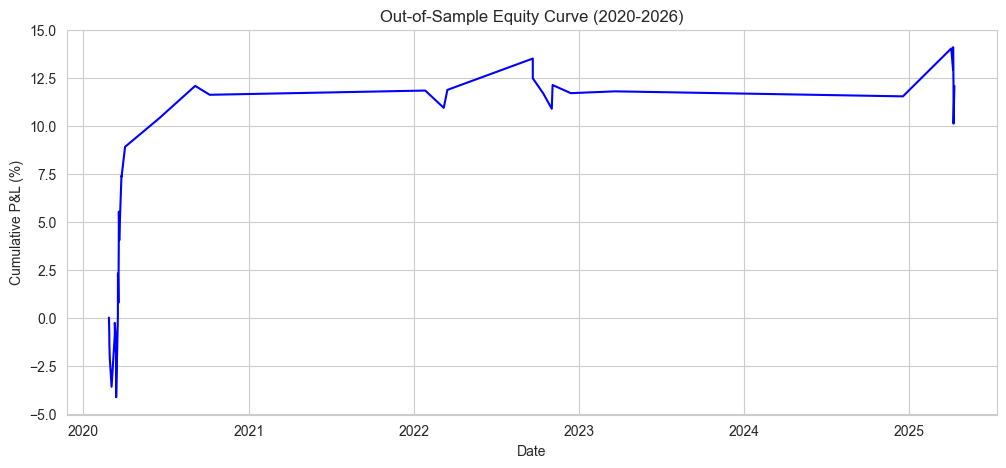

In [6]:
print("\n" + "="*70)
print("OUT-OF-SAMPLE VALIDATION (2020-2026) - ONE TIME TEST")
print("="*70)

df_prep_oos = prepare_data(df_oos, 
                          optimal_params['entry_threshold'],
                          optimal_params['rsi_threshold'],
                          optimal_params['atr_stop'],
                          optimal_params['atr_target'])

trades_oos = run_backtest(df_prep_oos, 
                         optimal_params['atr_stop'],
                         optimal_params['atr_target'])

metrics_oos = compute_metrics(trades_oos)

print(f"Number of trades: {metrics_oos['num_trades']}")
print(f"Win rate: {metrics_oos['win_rate']:.2f}%")
print(f"Average win: {metrics_oos['avg_win']:.2f}%")
print(f"Average loss: {metrics_oos['avg_loss']:.2f}%")
print(f"Profit Factor: {metrics_oos['profit_factor']:.2f}")
print(f"Expectancy per trade: {metrics_oos['expectancy']:.4f}%")
print(f"Total P&L: {metrics_oos['total_pnl']:.2f}%")
print(f"Sharpe Ratio (annualized): {metrics_oos['sharpe']:.2f}")
print(f"Maximum Drawdown: {metrics_oos['max_drawdown']:.2f}%")

# Equity curve
if len(trades_oos) > 0:
    trades_oos['cum_pnl'] = trades_oos['pnl'].cumsum()
    plt.figure(figsize=(12,5))
    plt.plot(trades_oos['exit_time'], trades_oos['cum_pnl'], color='blue', linewidth=1.5)
    plt.title('Out-of-Sample Equity Curve (2020-2026)')
    plt.xlabel('Date')
    plt.ylabel('Cumulative P&L (%)')
    plt.grid(True)
    plt.show()

# 3. COMPARE IN-SAMPLE VS OUT-OF-SAMPLE PERFORMANCE

In [7]:
print("\n" + "="*70)
print("PERFORMANCE COMPARISON: IS vs OOS")
print("="*70)

# Run backtest on IS with optimal params to compare
df_prep_is_final = prepare_data(df_is,
                               optimal_params['entry_threshold'],
                               optimal_params['rsi_threshold'],
                               optimal_params['atr_stop'],
                               optimal_params['atr_target'])

trades_is_final = run_backtest(df_prep_is_final,
                              optimal_params['atr_stop'],
                              optimal_params['atr_target'])

metrics_is_final = compute_metrics(trades_is_final)

comparison = pd.DataFrame({
    'Metric': ['Num Trades', 'Win Rate %', 'Profit Factor', 'Expectancy %', 'Total P&L %', 'Sharpe', 'Max DD %'],
    'In-Sample': [
        metrics_is_final['num_trades'],
        f"{metrics_is_final['win_rate']:.2f}",
        f"{metrics_is_final['profit_factor']:.2f}",
        f"{metrics_is_final['expectancy']:.4f}",
        f"{metrics_is_final['total_pnl']:.2f}",
        f"{metrics_is_final['sharpe']:.2f}",
        f"{metrics_is_final['max_drawdown']:.2f}"
    ],
    'Out-of-Sample': [
        metrics_oos['num_trades'],
        f"{metrics_oos['win_rate']:.2f}",
        f"{metrics_oos['profit_factor']:.2f}",
        f"{metrics_oos['expectancy']:.4f}",
        f"{metrics_oos['total_pnl']:.2f}",
        f"{metrics_oos['sharpe']:.2f}",
        f"{metrics_oos['max_drawdown']:.2f}"
    ]
})

print(comparison.to_string(index=False))

# Degradation assessment
pf_degradation = (metrics_is_final['profit_factor'] - metrics_oos['profit_factor']) / metrics_is_final['profit_factor'] * 100
expectancy_degradation = (metrics_is_final['expectancy'] - metrics_oos['expectancy']) / metrics_is_final['expectancy'] * 100

print(f"\nProfit Factor degradation: {pf_degradation:.1f}%")
print(f"Expectancy degradation: {expectancy_degradation:.1f}%")

if pf_degradation < 20 and expectancy_degradation < 20:
    print("✅ Good: The system is robust (degradation < 20%)")
elif pf_degradation < 35 and expectancy_degradation < 35:
    print("⚠️ Warning: Moderate degradation (20-35%). Consider refinements.")
else:
    print("❌ Alert: High degradation (>35%). The system may be overfitted to IS data.")


PERFORMANCE COMPARISON: IS vs OOS
       Metric In-Sample Out-of-Sample
   Num Trades        26            42
   Win Rate %     46.15         50.00
Profit Factor      1.37          1.60
 Expectancy %    0.1309        0.2877
  Total P&L %      3.40         12.08
       Sharpe      1.92          2.96
     Max DD %     -1.93         -4.14

Profit Factor degradation: -16.8%
Expectancy degradation: -119.7%
✅ Good: The system is robust (degradation < 20%)


# 4. PARAMETER SENSITIVITY ANALYSIS (ON OOS DATA)

In [8]:
print("\n" + "="*70)
print("PARAMETER SENSITIVITY ANALYSIS (OOS)")
print("="*70)

sensitivity_results = []

# Vary entry threshold ±20%
for threshold_var in [optimal_params['entry_threshold'] * 0.8, optimal_params['entry_threshold'] * 1.2]:
    df_prep = prepare_data(df_oos, threshold_var, optimal_params['rsi_threshold'], optimal_params['atr_stop'], optimal_params['atr_target'])
    trades = run_backtest(df_prep, optimal_params['atr_stop'], optimal_params['atr_target'])
    metrics = compute_metrics(trades)
    sensitivity_results.append({
        'param': 'entry_threshold',
        'value': threshold_var,
        'pf': metrics['profit_factor'],
        'expectancy': metrics['expectancy'],
        'num_trades': metrics['num_trades']
    })

# Vary RSI ±20%
for rsi_var in [optimal_params['rsi_threshold'] * 0.8, optimal_params['rsi_threshold'] * 1.2]:
    df_prep = prepare_data(df_oos, optimal_params['entry_threshold'], int(rsi_var), optimal_params['atr_stop'], optimal_params['atr_target'])
    trades = run_backtest(df_prep, optimal_params['atr_stop'], optimal_params['atr_target'])
    metrics = compute_metrics(trades)
    sensitivity_results.append({
        'param': 'rsi_threshold',
        'value': rsi_var,
        'pf': metrics['profit_factor'],
        'expectancy': metrics['expectancy'],
        'num_trades': metrics['num_trades']
    })

# Vary ATR stop ±20%
for stop_var in [optimal_params['atr_stop'] * 0.8, optimal_params['atr_stop'] * 1.2]:
    df_prep = prepare_data(df_oos, optimal_params['entry_threshold'], optimal_params['rsi_threshold'], stop_var, optimal_params['atr_target'])
    trades = run_backtest(df_prep, stop_var, optimal_params['atr_target'])
    metrics = compute_metrics(trades)
    sensitivity_results.append({
        'param': 'atr_stop',
        'value': stop_var,
        'pf': metrics['profit_factor'],
        'expectancy': metrics['expectancy'],
        'num_trades': metrics['num_trades']
    })

# Vary ATR target ±20%
for target_var in [optimal_params['atr_target'] * 0.8, optimal_params['atr_target'] * 1.2]:
    df_prep = prepare_data(df_oos, optimal_params['entry_threshold'], optimal_params['rsi_threshold'], optimal_params['atr_stop'], target_var)
    trades = run_backtest(df_prep, optimal_params['atr_stop'], target_var)
    metrics = compute_metrics(trades)
    sensitivity_results.append({
        'param': 'atr_target',
        'value': target_var,
        'pf': metrics['profit_factor'],
        'expectancy': metrics['expectancy'],
        'num_trades': metrics['num_trades']
    })

sens_df = pd.DataFrame(sensitivity_results)
print(sens_df.to_string(index=False))

# Check stability
pf_range = sens_df['pf'].max() - sens_df['pf'].min()
expectancy_range = sens_df['expectancy'].max() - sens_df['expectancy'].min()

print(f"\nProfit Factor range (OOS sensitivity): {pf_range:.2f}")
print(f"Expectancy range (OOS sensitivity): {expectancy_range:.4f}%")

if pf_range < 0.5 and abs(expectancy_range) < 0.05:
    print("✅ Robust: Performance is stable across parameter variations.")
else:
    print("⚠️ Warning: System is sensitive to parameter changes. Consider simplifying.")


PARAMETER SENSITIVITY ANALYSIS (OOS)
          param  value       pf  expectancy  num_trades
entry_threshold    0.8 1.172367    0.082747          81
entry_threshold    1.2 1.264999    0.162530          23
  rsi_threshold   12.0 1.860932    0.372153          39
  rsi_threshold   18.0 1.600932    0.283101          43
       atr_stop    1.2 2.077593    0.415613          44
       atr_stop    1.8 1.574538    0.296355          42
     atr_target    2.4 1.503555    0.242084          43
     atr_target    3.6 1.402351    0.214369          41

Profit Factor range (OOS sensitivity): 0.91
Expectancy range (OOS sensitivity): 0.3329%
⚠️ Warning: System is sensitive to parameter changes. Consider simplifying.


# 5. MONTE CARLO SIMULATION (ON OOS TRADES)


MONTE CARLO SIMULATION (Bootstrap - 10,000 iterations)
Monte Carlo results (10,000 bootstraps):
  5th percentile (final P&L): -4.11%
  50th percentile (final P&L): 11.97%
  95th percentile (final P&L): 28.68%
  99th percentile (final P&L): 35.81%
  Actual OOS P&L: 12.08%
  Probability of positive P&L: 88.9%
  Max drawdown (95th percentile worst): -2.98%
  Max drawdown (99th percentile worst): -2.32%


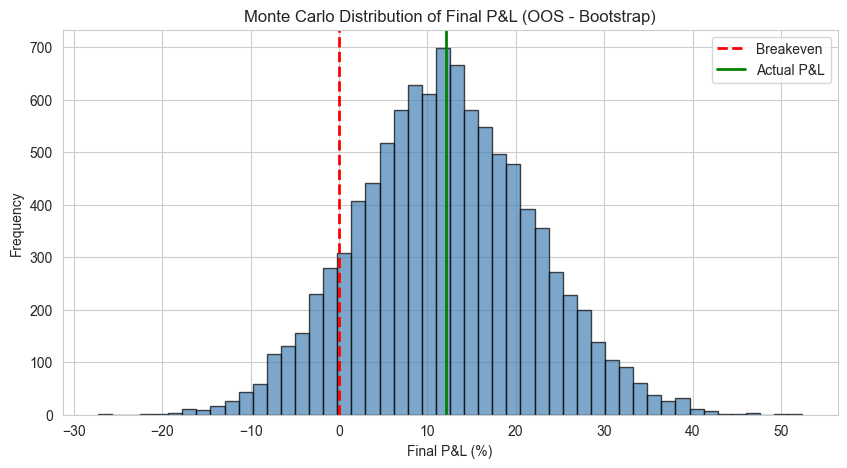

⚠️ Moderate edge: Actual P&L is above the median but not in the top 5%.


In [9]:
print("\n" + "="*70)
print("MONTE CARLO SIMULATION (Bootstrap - 10,000 iterations)")
print("="*70)

if len(trades_oos) > 0:
    pnl_array = trades_oos['pnl'].values
    n_trades = len(pnl_array)
    n_simulations = 10000
    
    mc_final_pnl = []
    mc_max_dd = []
    mc_profit_factor = []
    
    for _ in range(n_simulations):
        # Bootstrap: sample with replacement
        sampled = np.random.choice(pnl_array, size=n_trades, replace=True)
        cumulative = np.cumsum(sampled)
        mc_final_pnl.append(cumulative[-1])
        
        # Max drawdown
        running_max = np.maximum.accumulate(cumulative)
        dd = (cumulative - running_max)
        mc_max_dd.append(dd.min())
        
        # Profit factor
        wins = sampled[sampled > 0]
        losses = sampled[sampled < 0]
        pf = abs(wins.sum() / losses.sum()) if len(losses) > 0 and losses.sum() != 0 else np.inf
        mc_profit_factor.append(pf)
    
    mc_final_pnl = np.array(mc_final_pnl)
    mc_max_dd = np.array(mc_max_dd)
    mc_profit_factor = np.array(mc_profit_factor)
    
    # Percentiles
    p5 = np.percentile(mc_final_pnl, 5)
    p50 = np.percentile(mc_final_pnl, 50)
    p95 = np.percentile(mc_final_pnl, 95)
    p99 = np.percentile(mc_final_pnl, 99)
    
    print(f"Monte Carlo results (10,000 bootstraps):")
    print(f"  5th percentile (final P&L): {p5:.2f}%")
    print(f"  50th percentile (final P&L): {p50:.2f}%")
    print(f"  95th percentile (final P&L): {p95:.2f}%")
    print(f"  99th percentile (final P&L): {p99:.2f}%")
    print(f"  Actual OOS P&L: {metrics_oos['total_pnl']:.2f}%")
    
    # Probability of positive P&L
    prob_positive = np.mean(mc_final_pnl > 0) * 100
    print(f"  Probability of positive P&L: {prob_positive:.1f}%")
    
    # Max drawdown
    dd_p95 = np.percentile(mc_max_dd, 95)  # worst 5%
    dd_p99 = np.percentile(mc_max_dd, 99)  # worst 1%
    print(f"  Max drawdown (95th percentile worst): {dd_p95:.2f}%")
    print(f"  Max drawdown (99th percentile worst): {dd_p99:.2f}%")
    
    # Histogram of final P&L
    plt.figure(figsize=(10,5))
    plt.hist(mc_final_pnl, bins=50, alpha=0.7, color='steelblue', edgecolor='black')
    plt.axvline(x=0, color='red', linestyle='--', linewidth=2, label='Breakeven')
    plt.axvline(x=metrics_oos['total_pnl'], color='green', linestyle='-', linewidth=2, label='Actual P&L')
    plt.title('Monte Carlo Distribution of Final P&L (OOS - Bootstrap)')
    plt.xlabel('Final P&L (%)')
    plt.ylabel('Frequency')
    plt.legend()
    plt.grid(True)
    plt.show()
    
    # Check if actual P&L is above the 95th percentile (strong edge)
    if metrics_oos['total_pnl'] > p95:
        print("✅ Strong edge: Actual P&L is above the 95th percentile of bootstraps.")
    elif metrics_oos['total_pnl'] > p50:
        print("⚠️ Moderate edge: Actual P&L is above the median but not in the top 5%.")
    else:
        print("❌ Weak edge: Actual P&L is below the median of bootstraps.")
else:
    print("No trades in OOS data to simulate.")

# 6. FINAL SUMMARY & RECOMMENDATION

In [10]:
print("\n" + "="*70)
print("FINAL SUMMARY & RECOMMENDATION")
print("="*70)

print(f"\nOptimal Parameters (from IS optimization):")
print(f"  Entry Threshold: {optimal_params['entry_threshold']}%")
print(f"  RSI(2) Threshold: {optimal_params['rsi_threshold']}")
print(f"  ATR Stop Multiplier: {optimal_params['atr_stop']}x")
print(f"  ATR Target Multiplier: {optimal_params['atr_target']}x")
print(f"  Time Stop: 3:50 PM NY (to respect prop firm rule)")

print(f"\nOut-of-Sample Performance (2020-2026):")
print(f"  Number of Trades: {metrics_oos['num_trades']}")
print(f"  Win Rate: {metrics_oos['win_rate']:.2f}%")
print(f"  Profit Factor: {metrics_oos['profit_factor']:.2f}")
print(f"  Expectancy: {metrics_oos['expectancy']:.4f}% per trade")
print(f"  Total P&L: {metrics_oos['total_pnl']:.2f}%")
print(f"  Sharpe Ratio: {metrics_oos['sharpe']:.2f}")
print(f"  Maximum Drawdown: {metrics_oos['max_drawdown']:.2f}%")

print("\nDecision Criteria (based on TIS framework):")
if metrics_oos['profit_factor'] > 1.5 and metrics_oos['sharpe'] > 1.0 and metrics_oos['max_drawdown'] > -20:
    print("✅ PASS: The strategy has a robust edge. Proceed to forward testing (paper trading).")
elif metrics_oos['profit_factor'] > 1.3 and metrics_oos['sharpe'] > 0.7 and metrics_oos['max_drawdown'] > -25:
    print("⚠️ CONDITIONAL PASS: The strategy has a moderate edge. Refine parameters or combine with other systems.")
else:
    print("❌ FAIL: The strategy does not show a clear edge. Revisit hypothesis or discard.")

print("\n" + "="*70)
print("END OF ANALYSIS")
print("="*70)


FINAL SUMMARY & RECOMMENDATION

Optimal Parameters (from IS optimization):
  Entry Threshold: 1.0%
  RSI(2) Threshold: 15
  ATR Stop Multiplier: 1.5x
  ATR Target Multiplier: 3.0x
  Time Stop: 3:50 PM NY (to respect prop firm rule)

Out-of-Sample Performance (2020-2026):
  Number of Trades: 42
  Win Rate: 50.00%
  Profit Factor: 1.60
  Expectancy: 0.2877% per trade
  Total P&L: 12.08%
  Sharpe Ratio: 2.96
  Maximum Drawdown: -4.14%

Decision Criteria (based on TIS framework):
✅ PASS: The strategy has a robust edge. Proceed to forward testing (paper trading).

END OF ANALYSIS


# Next Steps (Based on TIS Framework)

After this professional optimization, the next steps are:

1. **Forward Testing (Paper Trading)**: Run the strategy live (paper trading) for 3-6 months to validate execution and psychology.
2. **Portfolio Diversification**: If the strategy passes forward testing, consider combining it with other uncorrelated strategies to reduce drawdown.
3. **Monitoring**: Track performance metrics weekly and watch for alpha decay.
4. **Walk-Forward Re-optimization**: Re-optimize parameters every 12-18 months using the same IS/OOS methodology.

Remember: The system is not perfect. It will have losing periods. The edge is probabilistic, not deterministic.